# 04_0. Trial of SHAP and LIME on M1 / Пробное применение SHAP и LIME к M1

**EN.** A first, trial application of two post-hoc explanation methods to the main model M1 (CatBoost, the average of its 5 fold models): **SHAP** (Shapley values: how much each feature moves the logit of this loan away from the average; additive) and **LIME** (a local linear model fitted to the predictions on random perturbations around one loan). Questions: which features drive the model overall; why a given loan is or is not on the alert list (the three risk-raising contributions = reason codes); do SHAP and LIME tell the same story for the same loan; is LIME stable from run to run. Data: validation half A (dates 2016-06 … 2017-03, main disaster rule), test is not used. Nothing here changes the models. The full explanation study with its own protocol (H6) is stage 4; this notebook is its trial run. Results: `reports/xai/trial/`.

**RU.** Первое, пробное применение двух пост-хок методов объяснения к основной модели M1 (CatBoost, среднее 5 фолдовых моделей): **SHAP** (значения Шепли: насколько каждый признак сдвигает логит этого кредита от среднего; аддитивны) и **LIME** (локальная линейная модель, подогнанная к прогнозам на случайных возмущениях вокруг одного кредита). Вопросы: какие признаки определяют модель в целом; почему конкретный кредит попал или не попал в список тревог (три вклада, повышающих риск, — коды причин); говорят ли SHAP и LIME одно и то же про один и тот же кредит; устойчив ли LIME от запуска к запуску. Данные — половина A validation (даты 2016-06 … 2017-03, основное правило бедствий); test не используется. Модели здесь не меняются. Полное исследование объяснений со своим протоколом (H6) — этап 4; этот ноутбук — его пробный запуск. Результаты — `reports/xai/trial/`.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import gc
import pickle
import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
import shap
from catboost import CatBoostClassifier
from lime.lime_tabular import LimeTabularExplainer
from scipy.stats import spearmanr
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
plt.rcParams.update({"figure.dpi": 80, "axes.grid": True, "grid.alpha": 0.3})

from xai_ews.config import feature_config
from xai_ews.evaluation.el import alert_threshold
from xai_ews.evaluation.metrics import auc
from xai_ews.models import catboost_model as cb
from xai_ews.models import registry
from xai_ews.models.data import load_eval, to_model_frame
from xai_ews.paths import MODELS_DIR, MODELING_DIR, XAI_DIR

OUT = XAI_DIR / "trial"
FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)
SEED = 20261025
SEL = feature_config()["selected"]
FEATS, CATS = SEL["features"], SEL["categorical"]
NUM = [f for f in FEATS if f not in CATS]
SHORT = {"borrower_credit_score_at_origination": "FICO", "co_borrower_credit_score_at_origination": "FICO co-borrower",
         "debt_to_income_dti": "DTI", "original_interest_rate": "interest rate", "original_upb": "original UPB",
         "mortgage_insurance_percentage": "MI %", "first_time_home_buyer_indicator": "first-time buyer",
         "hpi_chg_since_orig_rel_us": "HPI change rel. US", "excess_principal_12m": "excess principal 12m",
         "occupancy_status": "occupancy", "property_type": "property type", "loan_purpose": "loan purpose", "seller_name": "seller"}
NAMES = [SHORT.get(f, f) for f in FEATS]
THR = alert_threshold()

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")

# M1 = the 5 fold models, their category encoder and the Platt calibrator from validation half B
meta = registry.meta("m1_y1")
assert meta["features"] == FEATS
enc = pickle.loads((MODELS_DIR / "m1_y1" / "encoder.pkl").read_bytes())
folds = []
for k in range(cb.K_FOLDS):
    mk = CatBoostClassifier(); mk.load_model(str(MODELS_DIR / "m1_y1" / f"fold_{k}.cbm")); folds.append(mk)
platt = registry.calibrator("m1_y1")

# fixed row order: polars does not keep the scan order, and every random draw below indexes rows
va = load_eval("validation", "y1", FEATS, CATS).filter(pl.col("half") == "A").sort("loan_identifier", "m")
X = to_model_frame(va, FEATS, enc)
z = cb.fold_average_logit(folds, X, CATS)
pd_m1 = platt.predict(z)
y = va["y1"].to_numpy()
print(f"half A: {va.height:,} rows, {int(y.sum()):,} events; M1 AUC {auc(y, z):.4f}; alerts (PD >= {THR}) {np.mean(pd_m1 >= THR):.2%}")

half A: 853,029 rows, 1,695 events; M1 AUC 0.8629; alerts (PD >= 0.01) 3.57%


### 1. Is CatBoost's built-in SHAP exact? / Точен ли встроенный SHAP CatBoost?

**EN.** Before using SHAP we check its defining property, **additivity**: the contributions of a row plus the base value must equal the model's logit for that row. CatBoost's built-in SHAP (`ShapValues`) fails this check for M1. A small experiment on 150 000 rows of half A shows why: the built-in SHAP is exact for symmetric (oblivious) trees and for depth 2, but not for `Depthwise` / `Lossguide` trees deeper than 2 — with or without categorical features and missing values. M1 uses `Depthwise` trees of depth 4 (fixed in the protocol), so its built-in SHAP is only approximate (a defect of CatBoost 1.2.10, not of the model). Therefore all SHAP values below are computed **model-agnostically** with the permutation algorithm of the `shap` library on the M1 logit (the average of the 5 fold models; background = 100 random half-A rows): they add up to the logit exactly. The built-in values are kept only for comparison.

**RU.** Прежде чем пользоваться SHAP, проверяем его определяющее свойство — **аддитивность**: вклады строки плюс базовое значение должны давать логит модели для этой строки. Встроенный SHAP CatBoost (`ShapValues`) для M1 эту проверку не проходит. Небольшой опыт на 150 000 строк половины A показывает причину: встроенный SHAP точен для симметричных деревьев и для глубины 2, но не для деревьев `Depthwise` / `Lossguide` глубже 2 — с категориями и пропусками или без них. M1 построена на деревьях `Depthwise` глубины 4 (зафиксировано в протоколе), поэтому её встроенный SHAP лишь приближённый (дефект CatBoost 1.2.10, а не модели). Поэтому все значения SHAP ниже считаются **независимо от модели** — алгоритмом перестановок библиотеки `shap` по логиту M1 (среднее 5 фолдовых моделей; фон — 100 случайных строк половины A): они точно складываются в логит. Встроенные значения оставлены только для сравнения.

In [2]:
from catboost import Pool
DT = X.dtypes.to_dict()

def m1_logit(a):
    return cb.fold_average_logit(folds, pd.DataFrame(a, columns=FEATS).astype(DT), CATS)

def native_shap(frame):
    s = np.mean([m.get_feature_importance(cb.pool(frame, cat_features=CATS), type="ShapValues") for m in folds], axis=0)
    return s[:, :-1], s[:, -1]

rng = np.random.default_rng(SEED)
idx = rng.choice(va.height, size=1_100, replace=False)
bg = X.iloc[idx[:100]].values.astype(float)
Xs = X.iloc[idx[100:]].reset_index(drop=True)
nat, nat_base = native_shap(Xs)
z_s = m1_logit(Xs.values.astype(float))
nat_err = np.abs(nat.sum(1) + nat_base - z_s)

exp_rows = []
sub = va.sample(n=150_000, seed=1)
Xe, ye = to_model_frame(sub, FEATS, enc), sub["y1"].to_numpy()
for name, cols, cats, kw in [("symmetric, depth 4, all 18", FEATS, CATS, {}),
                             ("Depthwise, depth 2, all 18", FEATS, CATS, {"grow_policy": "Depthwise", "depth": 2}),
                             ("Depthwise, depth 4, all 18", FEATS, CATS, {"grow_policy": "Depthwise"}),
                             ("Depthwise, depth 4, numeric only, no missing", NUM, [], {"grow_policy": "Depthwise"}),
                             ("Lossguide, depth 4, numeric only, no missing", NUM, [], {"grow_policy": "Lossguide"})]:
    D = Xe[cols] if cats else Xe[cols].fillna(-999)
    mdl = CatBoostClassifier(iterations=200, verbose=0, random_seed=0, **{"depth": 4, "max_ctr_complexity": 1, **kw})
    mdl.fit(Pool(D, ye, cat_features=cats))
    pp = Pool(D.iloc[:2000], cat_features=cats)
    s = mdl.get_feature_importance(pp, type="ShapValues")
    exp_rows.append({"model (200 trees)": name, "max |sum SHAP - logit|": np.abs(s.sum(1) - mdl.predict(pp, prediction_type="RawFormulaVal")).max()})
exp_rows.append({"model (200 trees)": "M1 itself (5 x Depthwise depth 4), built-in SHAP", "max |sum SHAP - logit|": nat_err.max()})
additivity = pd.DataFrame(exp_rows)
additivity.to_csv(OUT / "native_shap_additivity.csv", index=False)
del sub, Xe; gc.collect()
print(f"M1 built-in SHAP: median error {np.median(nat_err):.3f}, 95th percentile {np.percentile(nat_err, 95):.3f} logit units")
additivity

M1 built-in SHAP: median error 0.120, 95th percentile 0.674 logit units


,model (200 trees),max |sum SHAP - logit|
0,"symmetric, depth 4, all 18",0.0000
1,"Depthwise, depth 2, all 18",0.0000
2,"Depthwise, depth 4, all 18",2.0594
3,"Depthwise, depth 4, numeric only, no missing",1.1777
4,"Lossguide, depth 4, numeric only, no missing",1.1847
5,"M1 itself (5 x Depthwise depth 4), built-in SHAP",1.7896


**EN. How to read.** CatBoost's built-in SHAP of M1 does not add up to its logit: the error is 0.12 logit units in the median, 0.67 at the 95th percentile and up to 1.79 (an error of 0.67 almost doubles the odds). The experiment locates the cause: symmetric trees of depth 4 and `Depthwise` trees of depth 2 are exact (error 0.0000), while `Depthwise` trees of depth 4 are not (2.06), also without categorical features and missing values (1.18), and neither are `Lossguide` trees (1.18). So the defect is in CatBoost 1.2.10's SHAP for non-symmetric trees deeper than 2, not in M1 or the data. Stage 2 used symmetric trees (depth 6), so its SHAP was exact; the stage-3 SHAP of M1 (`m1_shap_importance.csv`, the `occupancy_status` check in `03_7`) used the built-in values and is approximate. Section 2 shows how much that matters. The permutation SHAP below adds up to the logit within 6·10⁻⁵.

**RU. Как читать.** Встроенный SHAP CatBoost для M1 не складывается в её логит: ошибка — 0,12 единицы логита в медиане, 0,67 на 95-м процентиле и до 1,79 (ошибка 0,67 почти удваивает шансы). Опыт показывает причину: симметричные деревья глубины 4 и деревья `Depthwise` глубины 2 точны (ошибка 0,0000), а деревья `Depthwise` глубины 4 — нет (2,06), в том числе без категориальных признаков и пропусков (1,18); не точны и деревья `Lossguide` (1,18). Значит, дефект — в расчёте SHAP CatBoost 1.2.10 для несимметричных деревьев глубже 2, а не в M1 и не в данных. На этапе 2 использовались симметричные деревья (глубина 6), поэтому там SHAP был точным; SHAP модели M1 на этапе 3 (`m1_shap_importance.csv`, проверка `occupancy_status` в `03_7`) считался встроенным методом и приближённый. Насколько это важно — в разделе 2. SHAP методом перестановок ниже складывается в логит с точностью 6·10⁻⁵.

### 2. Global SHAP / Глобальная картина SHAP

**EN.** Permutation SHAP of the 18 features on 1 000 random rows of half A. Left: the share of the mean absolute contribution of each feature (global importance), next to the built-in CatBoost values on the same rows and the stage-3 table (`m1_shap_importance.csv`, built-in SHAP). Right: the beeswarm — every dot is a row; its position is the contribution to the logit (right = raises the risk), its colour the feature value (red = high; for categorical features the colour is the category code).

**RU.** SHAP методом перестановок для 18 признаков на 1 000 случайных строк половины A. Слева — доля среднего модуля вклада каждого признака (глобальная важность) рядом со встроенными значениями CatBoost на тех же строках и с таблицей этапа 3 (`m1_shap_importance.csv`, встроенный SHAP). Справа — «пчелиный рой»: каждая точка — строка; её положение — вклад в логит (вправо — повышает риск), цвет — значение признака (красный — высокое; у категориальных признаков цвет — код категории).

permutation SHAP: max |sum SHAP - logit| = 6.0e-05


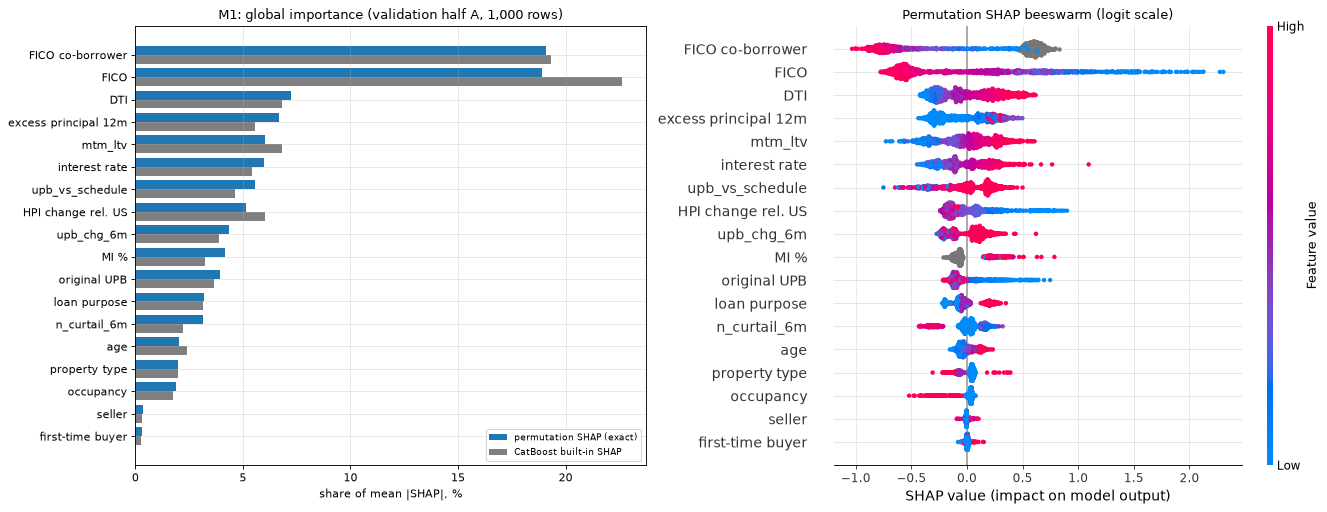

Spearman of the shares, exact vs built-in: 0.973; exact vs stage-3 table: 0.977


,feature,name,share,share_builtin,share_stage3_builtin
0,co_borrower_credit_score_at_origination,FICO co-borrower,0.1911,0.1930,0.1909
1,borrower_credit_score_at_origination,FICO,0.1889,0.2260,0.2341
2,debt_to_income_dti,DTI,0.0723,0.0680,0.0683
3,excess_principal_12m,excess principal 12m,0.0667,0.0557,0.0544
4,mtm_ltv,mtm_ltv,0.0604,0.0680,0.0645
5,original_interest_rate,interest rate,0.0597,0.0544,0.0542
6,upb_vs_schedule,upb_vs_schedule,0.0558,0.0461,0.0462
7,hpi_chg_since_orig_rel_us,HPI change rel. US,0.0516,0.0604,0.0602
8,upb_chg_6m,upb_chg_6m,0.0437,0.0387,0.0393
9,mortgage_insurance_percentage,MI %,0.0418,0.0324,0.0329


In [3]:
explainer = shap.PermutationExplainer(m1_logit, shap.maskers.Independent(bg, max_samples=100))

def perm_shap(frame, max_evals=400, seed=SEED):
    np.random.seed(seed)
    e = explainer(frame.values.astype(float), max_evals=max_evals, silent=True)
    return e.values, e.base_values

sv, base = perm_shap(Xs)
perm_err = np.abs(sv.sum(1) + base - z_s).max()
assert perm_err < 1e-3
print(f"permutation SHAP: max |sum SHAP - logit| = {perm_err:.1e}")
share = lambda v: np.abs(v).mean(0) / np.abs(v).mean(0).sum()
imp = pd.DataFrame({"feature": FEATS, "name": NAMES, "share": share(sv), "share_builtin": share(nat)})
ref = pd.read_csv(MODELING_DIR / "m1_shap_importance.csv", index_col=0)["y1"].rename("share_stage3_builtin")
imp = imp.merge(ref, left_on="feature", right_index=True, how="left").sort_values("share", ascending=False, ignore_index=True)
imp.to_csv(OUT / "shap_global.csv", index=False)

fig = plt.figure(figsize=(17, 6.5))
ax = fig.add_subplot(1, 2, 1)
yy = np.arange(len(imp))
ax.barh(yy - 0.2, 100 * imp["share"], height=0.4, color="C0", label="permutation SHAP (exact)")
ax.barh(yy + 0.2, 100 * imp["share_builtin"], height=0.4, color="C7", label="CatBoost built-in SHAP")
ax.set_yticks(yy, imp["name"]); ax.invert_yaxis(); ax.legend(fontsize=8)
ax.set_xlabel("share of mean |SHAP|, %"); ax.set_title("M1: global importance (validation half A, 1,000 rows)")
fig.add_subplot(1, 2, 2)
shap.summary_plot(sv, Xs.values.astype(float), feature_names=NAMES, show=False, plot_size=None, max_display=18)
plt.title("Permutation SHAP beeswarm (logit scale)")
plt.tight_layout(); save(fig, "01_shap_global"); plt.show()
print(f"Spearman of the shares, exact vs built-in: {spearmanr(imp['share'], imp['share_builtin']).statistic:.3f}; "
      f"exact vs stage-3 table: {spearmanr(imp['share'], imp['share_stage3_builtin']).statistic:.3f}")
imp

**EN. How to read.** The exact SHAP confirms the stage-3 picture in ranking but corrects the sizes. The Spearman correlation of the shares with the built-in values on the same rows is 0.973, with the stage-3 table 0.977; but the built-in SHAP overstates FICO (22.6 % instead of 18.9 %), house prices (6.0 instead of 5.2 %) and MTM LTV (6.8 instead of 6.0 %) and understates the behaviour features (excess principal 5.6 instead of 6.7 %, `upb_vs_schedule` 4.6 instead of 5.6 %, curtailments 2.2 instead of 3.1 %) and MI % (3.2 instead of 4.2 %). Exact shares: FICO and co-borrower FICO 19 % each, the borrower group (with DTI) 45 % (stage 3 said about 50 %), the seven dynamic features 33 % (stage 3: 31 %). The beeswarm agrees with the economics: a low FICO (blue) raises the risk strongly; a missing co-borrower FICO (grey: there is no co-borrower) adds about +0.6, a strong co-borrower (red) lowers it; a high DTI, interest rate and MTM LTV raise it; house prices falling relative to the US (blue) raise it; no mortgage insurance (grey, i.e. LTV ≤ 80 %) lowers it; small loans (blue) raise it, many curtailments (red `n_curtail_6m`) lower it; investors (red occupancy codes) lower it, the post-crisis pattern of train. `excess_principal_12m` raises the risk slightly when it is non-zero, the opposite of its raw relation; it shares information with `n_curtail_6m` and `upb_vs_schedule`, so the three should be read together (to be checked in stage 4).

**RU. Как читать.** Точный SHAP подтверждает картину этапа 3 по порядку признаков, но уточняет величины. Корреляция Спирмена долей со встроенными значениями на тех же строках — 0,973, с таблицей этапа 3 — 0,977; но встроенный SHAP завышает FICO (22,6 % вместо 18,9 %), цены на жильё (6,0 вместо 5,2 %) и MTM LTV (6,8 вместо 6,0 %) и занижает поведенческие признаки (сверхплановое погашение 5,6 вместо 6,7 %, `upb_vs_schedule` 4,6 вместо 5,6 %, частичные досрочные погашения 2,2 вместо 3,1 %) и MI % (3,2 вместо 4,2 %). Точные доли: FICO и FICO созаёмщика — по 19 %, группа «заёмщик» (с DTI) — 45 % (на этапе 3 — около 50 %), семь динамических признаков — 33 % (на этапе 3 — 31 %). «Пчелиный рой» согласуется с экономикой: низкий FICO (синий) сильно повышает риск; отсутствие FICO созаёмщика (серый — созаёмщика нет) добавляет около +0,6, сильный созаёмщик (красный) понижает; высокие DTI, ставка и MTM LTV повышают риск; падение цен на жильё относительно США (синий) повышает; отсутствие страховки (серый, то есть LTV ≤ 80 %) понижает; небольшие кредиты (синий) повышают, а частые частичные досрочные погашения (красный `n_curtail_6m`) понижают; инвесторы (красные коды) понижают — послекризисная картина train. `excess_principal_12m` при ненулевом значении немного повышает риск, вопреки его сырой связи; он делит информацию с `n_curtail_6m` и `upb_vs_schedule`, поэтому эти три признака нужно читать вместе (проверить на этапе 4).

### 3. Local SHAP: why this loan / Локальный SHAP: почему именно этот кредит

**EN.** Ten loans to explain, one random snapshot per loan, chosen at random within four groups by the alert (calibrated PD ≥ 0.01) and the outcome: 3 **caught** (alert and an event within 12 months), 3 **false alarms** (alert, no event), 3 **missed** (no alert, but an event) and 1 **quiet** loan (no alert, no event). For each: PD, the three features that raise the risk most (**reason codes**, as the bank would report them) and the strongest risk-lowering one (**mitigating**). Contributions are permutation SHAP values on the logit scale of M1 (800 evaluations per loan); the Platt calibration only rescales them (PD logit = a + b · M1 logit).

**RU.** Десять кредитов для объяснения, по одному случайному снимку на кредит, выбраны случайно внутри четырёх групп по тревоге (откалиброванная PD ≥ 0,01) и исходу: 3 **пойманных** (тревога и событие в течение 12 месяцев), 3 **ложных тревоги** (тревога, события нет), 3 **пропущенных** (тревоги нет, событие есть) и 1 **спокойный** кредит (ни тревоги, ни события). Для каждого — PD, три признака, сильнее всего повышающих риск (**коды причин**, как их показал бы банк), и самый сильный понижающий (**смягчающий**). Вклады — значения SHAP методом перестановок в шкале логита M1 (800 вычислений на кредит); калибровка Платта их только масштабирует (логит PD = a + b · логит M1).

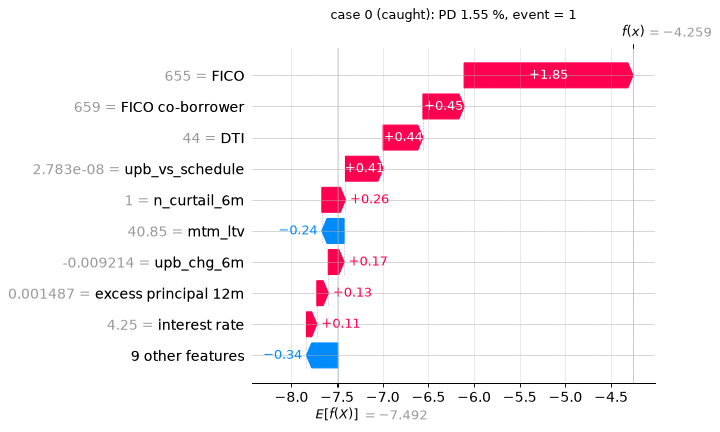

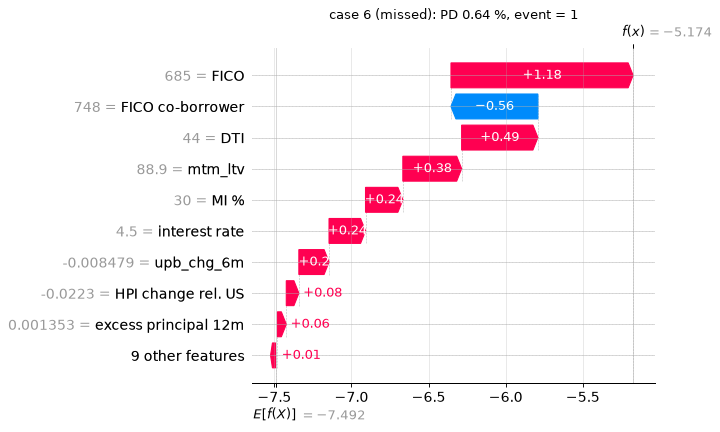

,case,group,pd_pct,event,reason_1,reason_2,reason_3,mitigating
0,0,caught,1.5546,1,FICO = 655 (+1.85),FICO co-borrower = 659 (+0.45),DTI = 44 (+0.44),mtm_ltv = 40.85 (-0.24)
1,1,caught,5.0634,1,FICO = 624 (+1.77),FICO co-borrower = missing (+0.59),original UPB = 3.9e+04 (+0.39),loan purpose = P (-0.05)
2,2,caught,2.3188,1,FICO = 621 (+1.99),FICO co-borrower = 659 (+0.40),upb_vs_schedule = 0.0009462 (+0.35),excess principal 12m = 1.088e-07 (-0.35)
3,3,false alarm,1.2889,0,FICO = 644 (+1.70),interest rate = 5.125 (+0.57),DTI = 44 (+0.35),HPI change rel. US = 0.05796 (-0.14)
4,4,false alarm,1.0742,0,FICO = 693 (+0.92),FICO co-borrower = missing (+0.63),interest rate = 4.625 (+0.30),excess principal 12m = 0.0007389 (-0.16)
5,5,false alarm,1.0144,0,FICO co-borrower = missing (+0.62),DTI = 44 (+0.48),FICO = 734 (+0.43),original UPB = 1.9e+05 (-0.11)
6,6,missed,0.6434,1,FICO = 685 (+1.18),DTI = 44 (+0.49),mtm_ltv = 88.9 (+0.38),FICO co-borrower = 748 (-0.56)
7,7,missed,0.6258,1,FICO = 714 (+0.69),FICO co-borrower = 645 (+0.48),interest rate = 4.875 (+0.40),excess principal 12m = 5.348e-08 (-0.31)
8,8,missed,0.6953,1,FICO = 659 (+1.79),FICO co-borrower = 634 (+0.49),DTI = 45 (+0.42),excess principal 12m = 9.897e-09 (-0.38)
9,9,quiet,0.0120,0,FICO co-borrower = missing (+0.60),excess principal 12m = 0.1294 (+0.23),age = 27 (+0.05),FICO = 788 (-0.54)


In [4]:
one = (va.with_row_index("row").with_columns(pl.Series("pd", pd_m1))
       .filter(pl.int_range(pl.len()).shuffle(seed=SEED).over("loan_identifier") == 0))
alert = pl.col("pd") >= THR
groups = {"caught": alert & (pl.col("y1") == 1), "false alarm": alert & (pl.col("y1") == 0),
          "missed": ~alert & (pl.col("y1") == 1), "quiet": ~alert & (pl.col("y1") == 0)}
size = {"caught": 3, "false alarm": 3, "missed": 3, "quiet": 1}
picked = pl.concat([one.filter(e).sample(n=size[g], seed=SEED).with_columns(pl.lit(g).alias("group")) for g, e in groups.items()])
rows = picked["row"].to_numpy()
Xc = X.iloc[rows].reset_index(drop=True)
shap_runs = {s: perm_shap(Xc, max_evals=800, seed=s) for s in (1, 2, 3)}
sc, base_c = shap_runs[1]
raw = va[rows].select(FEATS).to_pandas()

def fmt(f, v):
    if pd.isna(v): return "missing"
    return v if f in CATS else f"{v:,.4g}"

cases = []
for i in range(len(rows)):
    o = np.argsort(-sc[i])
    up = [f"{NAMES[j]} = {fmt(FEATS[j], raw.iloc[i, j])} (+{sc[i, j]:.2f})" for j in o[:3] if sc[i, j] > 0]
    dn = int(np.argmin(sc[i]))
    cases.append({"case": i, "group": picked["group"][i], "pd_pct": 100 * picked["pd"][i], "event": int(picked["y1"][i]),
                  "reason_1": up[0] if len(up) > 0 else "", "reason_2": up[1] if len(up) > 1 else "",
                  "reason_3": up[2] if len(up) > 2 else "",
                  "mitigating": f"{NAMES[dn]} = {fmt(FEATS[dn], raw.iloc[i, dn])} ({sc[i, dn]:.2f})"})
cases = pd.DataFrame(cases)
cases.to_csv(OUT / "local_reason_codes.csv", index=False)

for g in ["caught", "missed"]:
    i = int(cases.index[cases["group"] == g][0])
    ex = shap.Explanation(values=sc[i], base_values=base_c[i], data=Xc.iloc[i].values.astype(float),
                          display_data=np.array([str(fmt(f, raw.iloc[i, j])) for j, f in enumerate(FEATS)], dtype=object),
                          feature_names=NAMES)
    shap.plots.waterfall(ex, max_display=10, show=False)
    fig = plt.gcf(); fig.set_size_inches(9, 5.5)
    plt.title(f"case {i} ({g}): PD {cases.loc[i, 'pd_pct']:.2f} %, event = {cases.loc[i, 'event']}")
    plt.tight_layout(); save(fig, f"02_shap_waterfall_{g}"); plt.show()
cases

**EN. How to read.** The reason codes are readable. The three caught loans: low FICO 621–655 (+1.8 … +2.0), a weak co-borrower (FICO 659) or none, then DTI 44 %, a small loan ($39,000) or a balance above schedule. The false alarms look similar (FICO 644–734, no co-borrower, an interest rate of 4.6–5.1 %, DTI 44 %): the model is right that they are risky, they just did not default within 12 months — the precision of the alert list on half A is 1.8 %. The missed loans show why they were missed: all three have PD 0.63–0.70 %, three times the average but below the 1 % threshold, with the usual risk factors (FICO 659–714, DTI 44–45 %, MTM LTV 89 %); for case 6 a strong co-borrower (FICO 748, −0.56) pulled the PD down. The quiet loan has PD 0.01 %, mostly thanks to FICO 788 (−0.54). Mitigating factors are a strong co-borrower, a low MTM LTV, paying ahead of schedule and rising house prices. The base value is the average logit of M1 over the background rows.

**RU. Как читать.** Коды причин читаются. Три пойманных кредита: низкий FICO 621–655 (+1,8 … +2,0), слабый созаёмщик (FICO 659) или его нет, далее DTI 44 %, маленький кредит (39 000 $) или остаток выше графика. Ложные тревоги похожи (FICO 644–734, нет созаёмщика, ставка 4,6–5,1 %, DTI 44 %): модель права, что они рискованные, просто дефолта в течение 12 месяцев не случилось — точность списка тревог на половине A 1,8 %. Пропущенные кредиты показывают, почему их пропустили: у всех трёх PD 0,63–0,70 % — втрое выше средней, но ниже порога 1 %, при обычных факторах риска (FICO 659–714, DTI 44–45 %, MTM LTV 89 %); у кредита 6 PD снизил сильный созаёмщик (FICO 748, −0,56). У спокойного кредита PD 0,01 %, в основном благодаря FICO 788 (−0,54). Смягчающие факторы — сильный созаёмщик, низкий MTM LTV, погашение быстрее графика и рост цен на жильё. Базовое значение — средний логит M1 по фоновым строкам.

### 4. LIME on the same loans / LIME на тех же кредитах

**EN.** LIME on the same ten loans. The explainer perturbs a loan many times (5 000 samples drawn from the feature distribution of 20 000 half-A rows; numeric features are discretised into quartiles), asks M1 for the calibrated PD of every perturbed loan and fits a weighted linear model to these answers; its coefficients are the explanation. Two technical choices: categorical features are given to LIME as categories; a missing number is shown to LIME as −999 and turned back into a missing value before M1 is asked (LIME cannot work with missing values, M1 can). LIME is random, so it is run with three seeds.

**RU.** LIME на тех же десяти кредитах. Метод много раз «возмущает» кредит (5 000 вариантов из распределения признаков 20 000 строк половины A; числовые признаки разбиты на квартили), спрашивает у M1 откалиброванную PD каждого варианта и подгоняет к этим ответам взвешенную линейную модель; её коэффициенты и есть объяснение. Два технических решения: категориальные признаки передаются LIME как категории; пропущенное число показывается LIME как −999 и превращается обратно в пропуск перед вопросом к M1 (LIME не умеет работать с пропусками, M1 умеет). LIME случаен, поэтому запускается с тремя seed.

In [5]:
SENT = -999.0
cat_idx = [FEATS.index(c) for c in CATS]
inv = {FEATS.index(c): [k for k, _ in sorted(enc.maps[c].items(), key=lambda kv: kv[1])] for c in CATS}

def to_lime(frame):
    a = frame.values.astype(float)
    return np.where(np.isnan(a), SENT, a)

def predict_fn(a):
    f = pd.DataFrame(a, columns=FEATS)
    for c in NUM:
        f[c] = f[c].where(f[c] != SENT).astype(np.float32)
    for c in CATS:
        f[c] = f[c].round().astype(np.int32)
    p = platt.predict(cb.fold_average_logit(folds, f, CATS))
    return np.column_stack([1 - p, p])

assert np.allclose(predict_fn(to_lime(Xc))[:, 1], picked["pd"].to_numpy(), atol=1e-6)
lime_bg = to_lime(X.sample(n=20_000, random_state=SEED))
lime_runs = {}
for seed in (1, 2, 3):
    lime_exp = LimeTabularExplainer(lime_bg, mode="classification", feature_names=NAMES, categorical_features=cat_idx,
                                     categorical_names=inv, discretize_continuous=True, random_state=seed)
    w = np.zeros((len(rows), len(FEATS))); r2 = []
    for i in range(len(rows)):
        e = lime_exp.explain_instance(to_lime(Xc)[i], predict_fn, labels=(1,), num_features=len(FEATS), num_samples=5000)
        for j, wt in e.as_map()[1]:
            w[i, j] = wt
        r2.append(e.score)
        if seed == 1 and i == int(cases.index[cases["group"] == "caught"][0]):
            lime_example = e.as_list(label=1)
    lime_runs[seed] = (w, np.array(r2))
lw, lr2 = lime_runs[1]
pd.DataFrame(lime_example, columns=["condition (LIME bin)", "weight on PD"])

,condition (LIME bin),weight on PD
0,FICO <= 728.00,0.0083
1,-999.00 < FICO co-borrower <= 677.00,0.0021
2,upb_vs_schedule > -0.00,0.0018
3,mtm_ltv <= 51.07,-0.0012
4,0.00 < n_curtail_6m <= 1.00,0.0009
5,20.00 < age <= 32.00,-0.0009
6,4.00 < interest rate <= 4.38,0.0009
7,-0.00 < HPI change rel. US <= 0.03,-0.0008
8,MI % <= -999.00,-0.0008
9,-0.01 < upb_chg_6m <= -0.01,0.0007


### 5. SHAP vs LIME / Сравнение SHAP и LIME

**EN.** Agreement of the two methods for each loan: how many of the top-5 features (by absolute contribution) coincide; whether the shared features push in the same direction; the Spearman rank correlation of the absolute contributions over all 18 features; LIME's local R² (how well its linear model reproduces M1 around the loan); and the stability of each method — the average overlap of the top-5 between three seeds (both are random: LIME draws perturbations, permutation SHAP draws feature orders).

**RU.** Согласие двух методов по каждому кредиту: сколько признаков из топ-5 (по модулю вклада) совпадает; в одну ли сторону действуют общие признаки; ранговая корреляция Спирмена модулей вкладов по всем 18 признакам; локальный R² LIME (насколько хорошо его линейная модель воспроизводит M1 рядом с кредитом); и устойчивость каждого метода — среднее совпадение топ-5 между тремя seed (оба метода случайны: LIME выбирает возмущения, SHAP методом перестановок — порядки признаков).

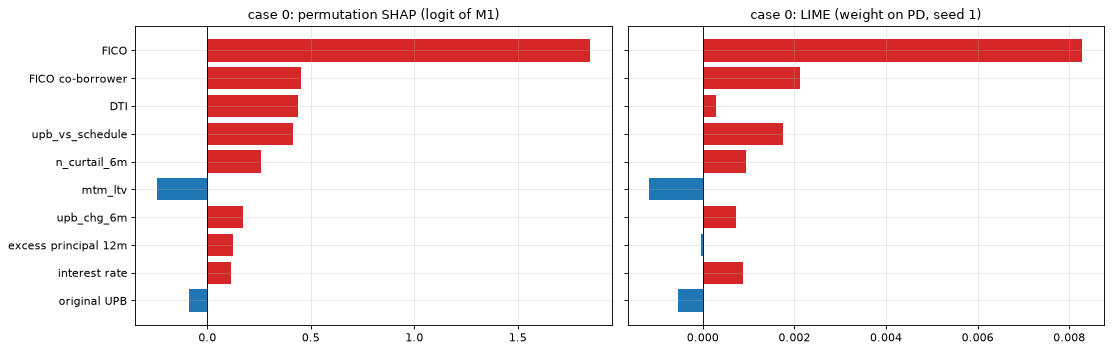

{'top5_shared': 3.4, 'same_sign_share': 0.967, 'spearman_abs': 0.624, 'lime_r2': 0.156, 'lime_top5_stability': 4.267, 'shap_top5_stability': 4.933}


,case,group,pd_pct,top5_shared,same_sign_share,spearman_abs,lime_r2,lime_top5_stability,shap_top5_stability,shap_top1,lime_top1
0,0,caught,1.5546,4,1.0000,0.6140,0.1856,3.6667,5.0000,FICO,FICO
1,1,caught,5.0634,4,1.0000,0.4696,0.2069,5.0000,5.0000,FICO,FICO
2,2,caught,2.3188,4,1.0000,0.6780,0.1892,3.6667,5.0000,FICO,FICO
3,3,false alarm,1.2889,3,1.0000,0.7750,0.2051,4.3333,5.0000,FICO,FICO
4,4,false alarm,1.0742,4,1.0000,0.7152,0.2029,5.0000,5.0000,FICO,FICO
5,5,false alarm,1.0144,3,0.6667,0.7028,0.0433,3.6667,5.0000,FICO co-borrower,FICO co-borrower
6,6,missed,0.6434,4,1.0000,0.7317,0.1512,4.3333,4.3333,FICO,FICO
7,7,missed,0.6258,3,1.0000,0.4757,0.1436,4.3333,5.0000,FICO,FICO
8,8,missed,0.6953,2,1.0000,0.5686,0.1581,3.6667,5.0000,FICO,FICO
9,9,quiet,0.0120,3,1.0000,0.5108,0.0761,5.0000,5.0000,FICO co-borrower,excess principal 12m


In [6]:
def top(v, k=5):
    return set(np.argsort(-np.abs(v))[:k])

cmp = []
for i in range(len(rows)):
    ts, tl = top(sc[i]), top(lw[i])
    shared = ts & tl
    same_sign = np.mean([np.sign(sc[i, j]) == np.sign(lw[i, j]) for j in shared]) if shared else np.nan
    stab = np.mean([len(top(lime_runs[a][0][i]) & top(lime_runs[b][0][i])) for a, b in ((1, 2), (1, 3), (2, 3))])
    stab_s = np.mean([len(top(shap_runs[a][0][i]) & top(shap_runs[b][0][i])) for a, b in ((1, 2), (1, 3), (2, 3))])
    cmp.append({"case": i, "group": cases.loc[i, "group"], "pd_pct": cases.loc[i, "pd_pct"],
                "top5_shared": len(shared), "same_sign_share": same_sign,
                "spearman_abs": spearmanr(np.abs(sc[i]), np.abs(lw[i])).statistic, "lime_r2": lr2[i],
                "lime_top5_stability": stab, "shap_top5_stability": stab_s,
                "shap_top1": NAMES[int(np.argmax(np.abs(sc[i])))], "lime_top1": NAMES[int(np.argmax(np.abs(lw[i])))]})
cmp = pd.DataFrame(cmp)
cmp.to_csv(OUT / "shap_vs_lime.csv", index=False)

i = int(cases.index[cases["group"] == "caught"][0])
o = np.argsort(-np.abs(sc[i]))[:10][::-1]
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
ax[0].barh([NAMES[j] for j in o], sc[i, o], color=["C3" if v > 0 else "C0" for v in sc[i, o]]); ax[0].set_title(f"case {i}: permutation SHAP (logit of M1)")
ax[1].barh([NAMES[j] for j in o], lw[i, o], color=["C3" if v > 0 else "C0" for v in lw[i, o]]); ax[1].set_title(f"case {i}: LIME (weight on PD, seed 1)")
for a in ax: a.axvline(0, color="k", lw=0.8)
plt.tight_layout(); save(fig, "03_shap_vs_lime_case"); plt.show()
print(cmp[["top5_shared", "same_sign_share", "spearman_abs", "lime_r2", "lime_top5_stability", "shap_top5_stability"]].mean().round(3).to_dict())
cmp

**EN. How to read.** SHAP and LIME agree on the main thing: the top feature is the same in 9 of the 10 loans (FICO in 8, co-borrower FICO in 1); the exception is the quiet loan with PD 0.01 %, where LIME's weights are tiny and its fit poor (R² 0.08). On average 3.4 of the top 5 features coincide, and the shared features push in the same direction in 97 % of cases. The details differ: the rank correlation of the absolute contributions over all 18 features is only 0.62 (0.47–0.78). LIME's local linear model explains only 16 % of M1's PD around a loan (R² 0.04–0.21): the model is non-linear and LIME's quartile bins are coarse, so its weights are a rough approximation. LIME is less stable: the top 5 overlap between seeds by 4.3 of 5 (3.7 at worst), permutation SHAP by 4.9. LIME also needs workarounds that SHAP does not: missing values have to be coded (−999), so for features with many missing values one quartile bin is taken by them (`MI % <= -999` above is "no mortgage insurance"), and its weights are on the PD scale, which is tiny for rare events. Conclusion: SHAP for the reason codes, LIME as a cross-check.

**RU. Как читать.** SHAP и LIME согласны в главном: главный признак совпадает у 9 из 10 кредитов (FICO у 8, FICO созаёмщика у 1); исключение — спокойный кредит с PD 0,01 %, где веса LIME крошечные, а приближение плохое (R² 0,08). В среднем совпадают 3,4 из топ-5 признаков, и общие признаки действуют в одну сторону в 97 % случаев. В деталях методы расходятся: ранговая корреляция модулей вкладов по всем 18 признакам — лишь 0,62 (0,47–0,78). Локальная линейная модель LIME объясняет лишь 16 % PD модели M1 рядом с кредитом (R² 0,04–0,21): модель нелинейная, а квартильные корзины LIME грубые, поэтому его веса — грубое приближение. LIME менее устойчив: топ-5 между seed совпадает на 4,3 из 5 (в худшем случае 3,7), у SHAP методом перестановок — на 4,9. LIME требует обходных решений, которых не требует SHAP: пропуски приходится кодировать (−999), поэтому у признаков с большим числом пропусков одна квартильная корзина уходит на них (`MI % <= -999` выше — это «нет страховки»), а его веса — в шкале PD, которая для редкого события очень мала. Вывод: коды причин — по SHAP, LIME — как перекрёстная проверка.

### 6. Reason codes on the alert list / Коды причин в списке тревог

**EN.** Two checks of the reason codes on 300 random alerted rows of half A (calibrated PD ≥ 0.01): how often each feature is among the three risk-raising contributions, and how many alerted loans have fewer than three risk-raising contributions at all.

**RU.** Две проверки кодов причин на 300 случайных строках половины A из списка тревог (откалиброванная PD ≥ 0,01): как часто каждый признак входит в три повышающих риск вклада и у скольких кредитов из списка вообще меньше трёх вкладов, повышающих риск.

alerted rows explained: 300; with fewer than 3 risk-raising contributions: 0


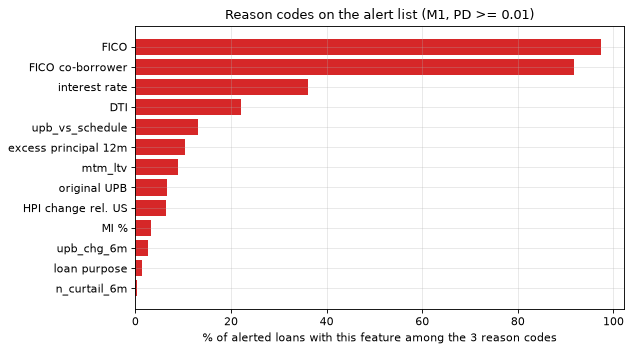

,share_of_alerted_pct
FICO,97.3333
FICO co-borrower,91.6667
interest rate,36.0000
DTI,22.0000
upb_vs_schedule,13.0000
excess principal 12m,10.3333
mtm_ltv,9.0000
original UPB,6.6667
HPI change rel. US,6.3333
MI %,3.3333


In [7]:
al_rows = np.flatnonzero(pd_m1 >= THR)
al_rows = np.random.default_rng(SEED).choice(al_rows, size=300, replace=False)
sa, _ = perm_shap(X.iloc[al_rows].reset_index(drop=True))
top3 = np.argsort(-sa, axis=1)[:, :3]
pos = np.take_along_axis(sa, top3, axis=1) > 0
freq = pd.Series([NAMES[j] for j, ok in zip(top3.ravel(), pos.ravel()) if ok]).value_counts()
reason_freq = (100 * freq / len(al_rows)).rename("share_of_alerted_pct").to_frame()
reason_freq.to_csv(OUT / "reason_code_frequency.csv")
print(f"alerted rows explained: {len(al_rows)}; with fewer than 3 risk-raising contributions: {(pos.sum(1) < 3).sum()}")
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(reason_freq.index, reason_freq["share_of_alerted_pct"], color="C3"); ax.invert_yaxis()
ax.set_xlabel("% of alerted loans with this feature among the 3 reason codes"); ax.set_title("Reason codes on the alert list (M1, PD >= 0.01)")
plt.tight_layout(); save(fig, "04_reason_codes"); plt.show()
reason_freq

**EN. How to read.** Every one of the 300 alerted loans has three risk-raising contributions. The reason codes are dominated by two borrower features: FICO is among them for 97 % of alerted loans and the co-borrower FICO (mostly "no co-borrower" or a weak one) for 92 %; then the interest rate 36 %, DTI 22 %, `upb_vs_schedule` 13 %, excess principal 10 %, and MTM LTV, the loan amount and house prices 6–9 % each. So for a bank officer the explanation of almost every alert would be "low FICO, no or weak co-borrower", and the dynamic signals appear only as the third reason. This is a substantive finding for stage 4: reason codes may need a separate line for what has changed since origination (the dynamic features), otherwise the early-warning signal is hidden behind the static ones.

**RU. Как читать.** У каждого из 300 кредитов из списка тревог есть три вклада, повышающих риск. В кодах причин доминируют два признака заёмщика: FICO входит в них у 97 % кредитов из списка, FICO созаёмщика (в основном «нет созаёмщика» или слабый созаёмщик) — у 92 %; далее ставка — 36 %, DTI — 22 %, `upb_vs_schedule` — 13 %, сверхплановое погашение — 10 %, MTM LTV, сумма кредита и цены на жильё — по 6–9 %. Значит, для сотрудника банка объяснением почти любой тревоги будет «низкий FICO, нет созаёмщика или он слабый», а динамические сигналы появятся только третьей причиной. Это содержательный вывод для этапа 4: в кодах причин, возможно, нужна отдельная строка «что изменилось с момента выдачи» (динамические признаки), иначе сигнал раннего предупреждения скрыт за статическими признаками.

**EN. Summary.** The trial covers week 8 of the practice plan: SHAP and LIME were applied to the main model. Four findings. (1) CatBoost's built-in SHAP is not exact for M1's `Depthwise` trees (a library defect); all explanations are therefore computed with exact permutation SHAP, and the stage-3 SHAP shares are approximate — the ranking holds (Spearman 0.97–0.98), the sizes shift by up to 4 percentage points (FICO 19 % instead of 23 %). (2) M1 relies on the borrower (45 %) and on the dynamic features (33 %), with signs that agree with the economics. (3) The reason codes are readable but dominated by FICO and the co-borrower; the dynamic signals need a place of their own. (4) LIME agrees with SHAP on the main feature but fits M1 poorly (R² 0.16) and is less stable, so SHAP is the primary method and LIME a cross-check. Nothing here changes the models; stage 4 builds on this with its own protocol.

**RU. Итог.** Пробный запуск закрывает неделю 8 плана практики: SHAP и LIME применены к основной модели. Четыре вывода. (1) Встроенный SHAP CatBoost неточен для деревьев `Depthwise` модели M1 (дефект библиотеки); поэтому все объяснения считаются точным SHAP методом перестановок, а доли SHAP этапа 3 приближённые — порядок признаков сохраняется (Спирмен 0,97–0,98), величины сдвигаются до 4 п.п. (FICO 19 % вместо 23 %). (2) M1 опирается на признаки заёмщика (45 %) и на динамические признаки (33 %), знаки согласуются с экономикой. (3) Коды причин читаются, но в них доминируют FICO и созаёмщик; динамическим сигналам нужно отдельное место. (4) LIME согласен с SHAP в главном признаке, но плохо приближает M1 (R² 0,16) и менее устойчив, поэтому SHAP — основной метод, LIME — перекрёстная проверка. Модели здесь не меняются; этап 4 продолжит эту работу по своему протоколу.